# Exercise 8.01 - Plotting Poaching Density Using Dot Density and Histograms

In this exercise we look at the primary use of geoplotlib's plot methods for **dot density**, **histograms** and **Voronoi diagrams**, using data on poaching incidents that have taken place all over the world (268 poaching incidents in Tanzania).

Student ID: **MC659782**

In [1]:
# Capture geoplotlib maps as images inside this notebook
# (the interactive window is rendered off-screen and saved as a PNG)
import geoplotlib as geoplotlib
from IPython.display import Image as _Img, display as _disp
import os as _os, time as _time
_counter = {'n': 0}
_orig_show = geoplotlib.show
def _show_capture(*a, **k):
    _counter['n'] += 1
    fname = '_map_%d' % _counter['n']
    for _attempt in range(3):
        try:
            geoplotlib.savefig(fname)
        except Exception:
            pass
        if _os.path.exists(fname + '.png'):
            break
        _time.sleep(1)
    _disp(_Img(fname + '.png'))
    if _os.path.exists(fname + '.png'):
        _os.remove(fname + '.png')
geoplotlib.show = _show_capture

In [2]:
# Import the dependencies
import geoplotlib
from geoplotlib.utils import read_csv

In [3]:
# Load the dataset with geoplotlib's read_csv -> DataAccessObject
dataset = read_csv('Datasets/poaching_points_cleaned.csv')

In [4]:
# Looking at the dataset structure
dataset

DataAccessObject(dict_keys(['id_report', 'date_report', 'description', 'created_date', 'lat', 'lon']) x 268)

In [5]:
# csv import with pandas
import pandas as pd
pd_dataset = pd.read_csv('Datasets/poaching_points_cleaned.csv')
pd_dataset.head()

,id_report,date_report,description,created_date,lat,lon
0,138,01/01/2005 12:00:00 AM,Poaching incident,2005/01/01 12:00:00 AM,-7.049359,34.841440
1,4,01/20/2005 12:00:00 AM,Poaching incident,2005/01/20 12:00:00 AM,-7.650840,34.480010
2,43,01/20/2005 12:00:00 AM,Poaching incident,2005/02/20 12:00:00 AM,-7.843202,34.005704
3,98,01/20/2005 12:00:00 AM,Poaching incident,2005/02/21 12:00:00 AM,-7.745846,33.948526
4,141,01/20/2005 12:00:00 AM,Poaching incident,2005/02/22 12:00:00 AM,-7.876673,33.690167


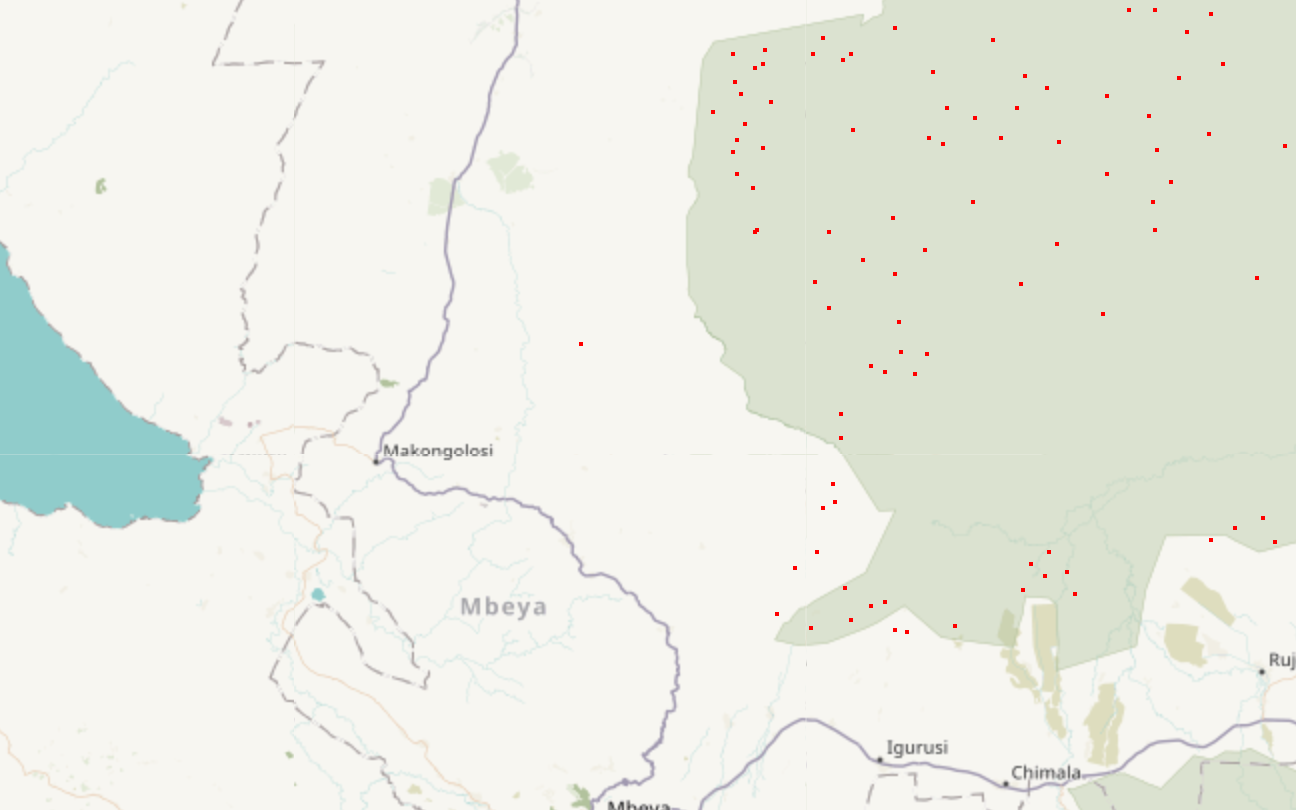

In [6]:
# Plotting our dataset with points (dot density layer)
geoplotlib.dot(dataset)
geoplotlib.show()

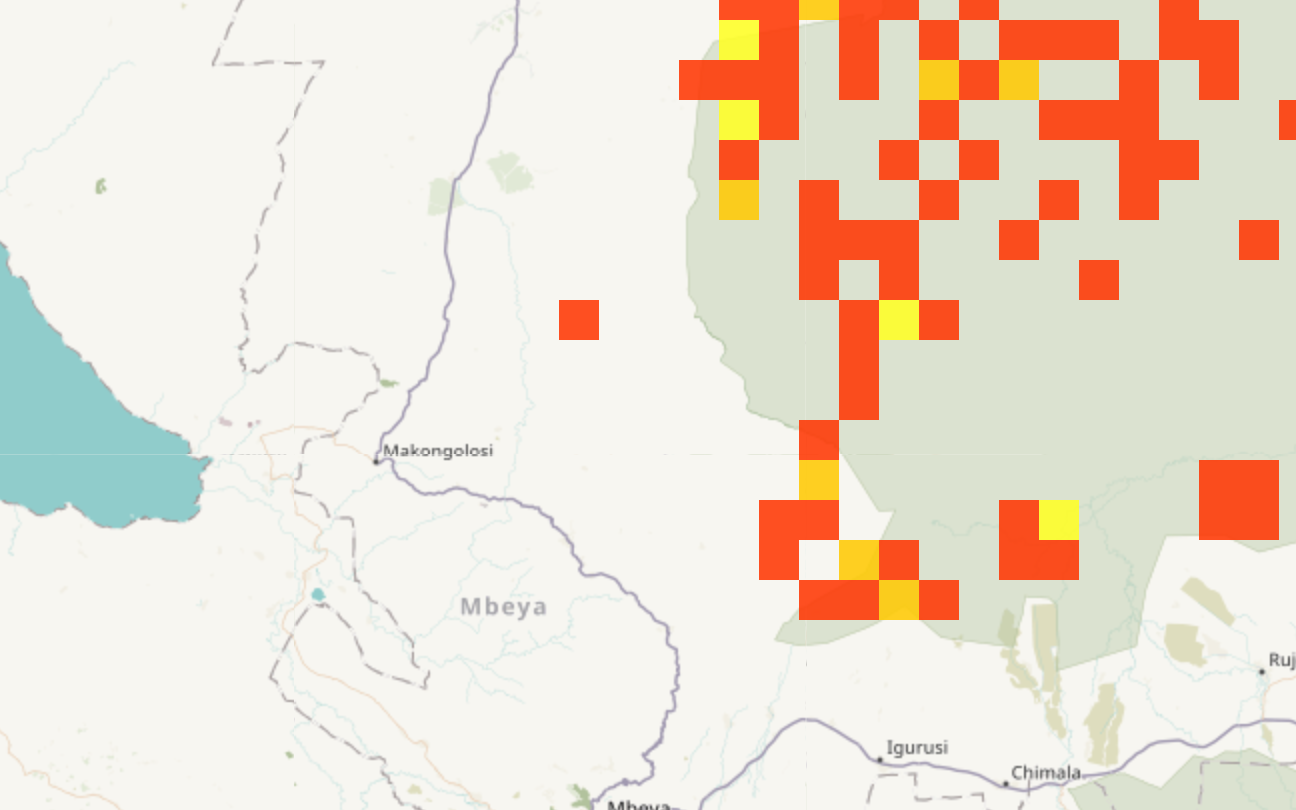

In [7]:
# Plotting our dataset as a histogram (binsize 20)
geoplotlib.hist(dataset, binsize=20)
geoplotlib.show()

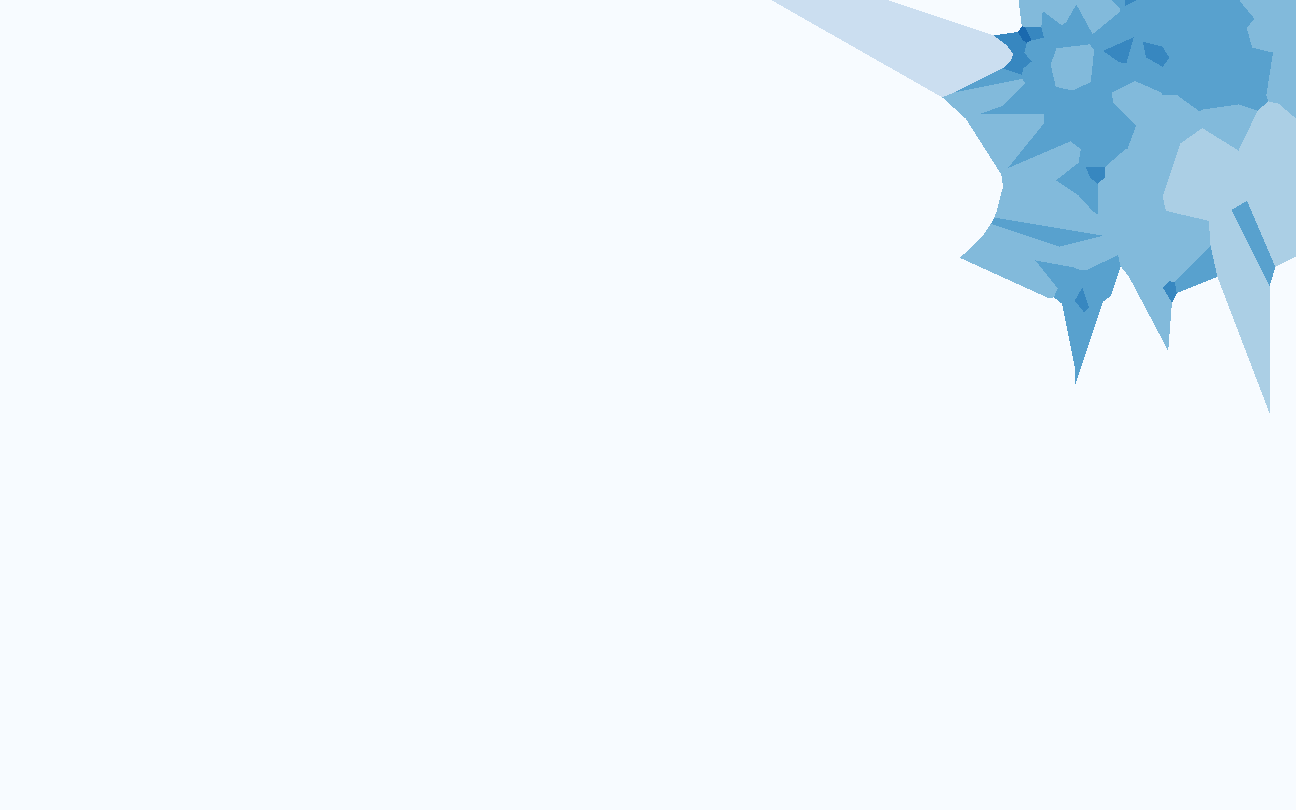

In [8]:
# Plotting a Voronoi map (cmap='Blues_r', max_area=1e5, alpha=255)
from geoplotlib.utils import BoundingBox
tanzania_bbox = BoundingBox(north=dataset['lat'].max() + 0.5,
                            south=dataset['lat'].min() - 0.5,
                            west=dataset['lon'].min() - 0.5,
                            east=dataset['lon'].max() + 0.5)
geoplotlib.voronoi(dataset, cmap='Blues_r', max_area=1e5, alpha=255)
geoplotlib.set_bbox(tanzania_bbox)
geoplotlib.show()

**Observation**: The dot density plot already shows that some areas have more poaching incidents than others. The histogram highlights hotspots of poaching density, and the Voronoi diagram reveals an even larger hotspot in the centre-right edge of the plot that could easily be overlooked with the histogram.

Notebook saved as `MC659782_Exercise8.01.ipynb`.